In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os 
import gc
from itertools import islice
%matplotlib inline

import torch
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader, Subset
import torch.nn as nn

# Determining if a Celebrity is Smiling

In this homework, we will download a relatively large data set (1.5GB) of images of celebrities and determine which of them are smiling or not.  In the data set, the images have labeled attributes, one of which being if the person in the photo is smiling.  Thus we are performing a binary classification of an image, but we are doing it on a relatively small feature in the larger image.  

## Getting the CelebA Data Set

This could take a minute!  To enrich our data set, note that we add randomly cropped and flipped versions of the images to the training data set.  This echoes the way we built redundant dictionaries of images in Homework 9.  

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

image_path = './' # just store everything to your local working directory
CelebA_data_path = image_path + '/celeba'
torch.manual_seed(1)

transform_train = transforms.Compose([
    transforms.RandomCrop([178,178]),
    transforms.RandomHorizontalFlip(),
    transforms.Resize([64, 64]),
    transforms.ToTensor()
    ])

transform = transforms.Compose([
    transforms.CenterCrop([178,178]),
    transforms.Resize([64, 64]),
    transforms.ToTensor()
    ])

get_smile = lambda attr: attr[31]
dval = False
if not os.path.isdir(CelebA_data_path): # if you've already downloaded and converted the MNIST images, skip
    dval = True    

# Download and convert CelebA images into tensor format. 
celeba_dataset_train = torchvision.datasets.CelebA(image_path, split='train', target_type='attr', download=dval, 
                                                   transform=transform_train, target_transform=get_smile)
    
celeba_dataset_valid = torchvision.datasets.CelebA(image_path, split='valid', transform=transform, 
                                                       target_type='attr', download=dval, target_transform=get_smile)
    
celeba_dataset_test = torchvision.datasets.CelebA(image_path, split='test', transform=transform, 
                                                       target_type='attr', download=dval, target_transform=get_smile)    

cuda


You should see some faces from different perspectives when you run the next cell. If not, something is wrong.  

Feature batch shape: torch.Size([2, 3, 64, 64])
Labels batch shape: torch.Size([2])


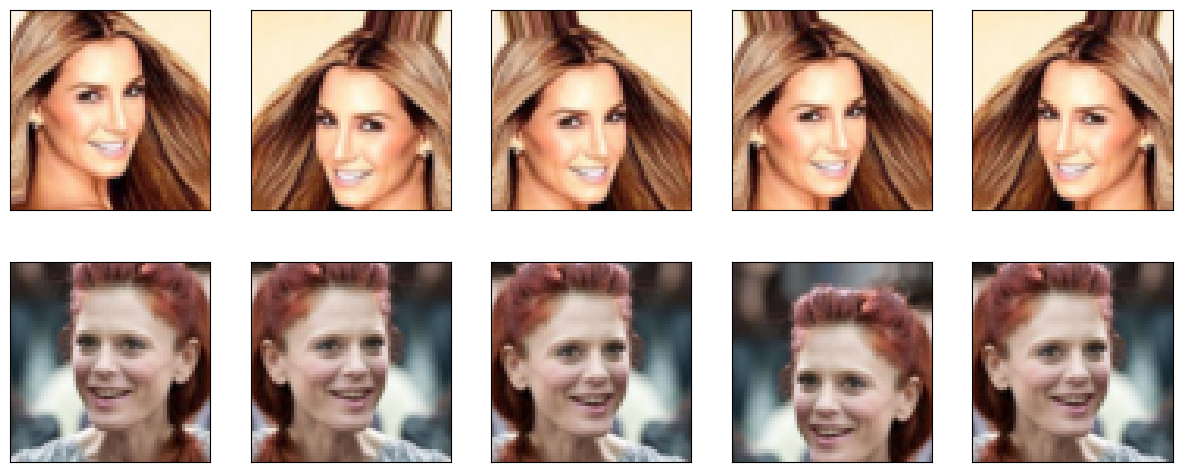

In [3]:
fig = plt.figure(figsize=(15,6))
data_loader = DataLoader(celeba_dataset_train, batch_size=2)
num_perspectives = 5
for jj in range(num_perspectives):
    img_batch, label_batch = next(iter(data_loader))

    # also print shape of single batch
    # Print the tensor shapes
    if (jj == 0):
        print("Feature batch shape:", img_batch.size())  
        print("Labels batch shape:", label_batch.size())  

    img = img_batch[0]
    ax = fig.add_subplot(2,5,jj+1)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.imshow(img.permute(1,2,0))
    
    img = img_batch[1]
    ax = fig.add_subplot(2,5,jj+6)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.imshow(img.permute(1,2,0))
    

In [4]:
# print out dataset sizes
print(f"Training set size: {len(celeba_dataset_train)}")
print(f"Validation set size: {len(celeba_dataset_valid)}")
print(f"Test set size: {len(celeba_dataset_test)}")



Training set size: 162770
Validation set size: 19867
Test set size: 19962


Here we decide on a batch size for running Stochastic Gradient Descent and then get our training data into the proper format for iterating over epochs with a random shuffle into new batches at every iteration.  

In [5]:
batch_size = 32
# we use a smaller version of the training and validation sets to speed up training
celeba_dataset_train = Subset(celeba_dataset_train, torch.arange(16000))
celeba_dataset_valid = Subset(celeba_dataset_valid, torch.arange(1000))

pmem = False
if torch.cuda.is_available():
    pmem = True

train_dl = DataLoader(celeba_dataset_train, batch_size, shuffle=True, pin_memory=pmem)
valid_dl = DataLoader(celeba_dataset_valid, batch_size, shuffle=False, pin_memory=pmem)
test_dl = DataLoader(celeba_dataset_test, batch_size, shuffle=False, pin_memory=pmem)

## Problem: Building the Model

Using the Convolutional_Networks_and_Pooling_Layers notebook as a model, implement the following network architecture.  

In [7]:
model = nn.Sequential()

# here we are going to follow the common rule of thumb of increasing channels as spatial resolution decreases (as we get deeper into the CNN)
# start with 32 and end with 128

# we can also increase dropout percentages as we get closer to the classification head

# First convoultional/relu/pooling/dropout layer
model.add_module(
    'conv1',
    nn.Conv2d(
        in_channels=3, out_channels=32,
        kernel_size=3, stride=1, padding=1 # preserves height and width
    )
)
# add relu, pooling, dropout
model.add_module('relu1', nn.ReLU())
model.add_module('pool1', nn.MaxPool2d(kernel_size=2, stride=2))
model.add_module('dropout1', nn.Dropout(p=0.1))


# Second convoultional/relu/pooling/dropout layer
model.add_module(
    'conv2',
    nn.Conv2d(
        in_channels=32, out_channels=64,
        kernel_size=3, stride=1, padding=1
    )
)
model.add_module('relu2', nn.ReLU())
model.add_module('pool2', nn.MaxPool2d(kernel_size=2, stride=2))
model.add_module('dropout2', nn.Dropout(p=0.1))

# Third convoultional/relu/pooling layer
model.add_module(
    'conv3',
    nn.Conv2d(
        in_channels=64, out_channels=128,
        kernel_size=3, stride=1, padding=1
    )
)
model.add_module('relu3', nn.ReLU())
model.add_module('pool3', nn.MaxPool2d(kernel_size=2, stride=1))
model.add_module('dropout3', nn.Dropout(p=0.25)) # set to 0.25 now


# Fourth convoultional/relu/pooling layer
model.add_module(
    'conv4',
    nn.Conv2d(
        in_channels=128, out_channels=128,
        kernel_size=3, stride=1, padding=1
    )
)
model.add_module('relu4', nn.ReLU())
model.add_module('pool4', nn.MaxPool2d(kernel_size=2, stride=1))
model.add_module('dropout4', nn.Dropout(p=0.25))

# Fully connected classifier label like we had before
model.add_module('flatten', nn.Flatten()) # should receive input that is 14x14x128 = 25088

x = torch.ones((4, 3, 64, 64))
dims = model(x).shape
# print(dims)

model.add_module('fc', nn.Linear(dims[1],1))
model.add_module('sigmoid', nn.Sigmoid())
model.to(device)

Sequential(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout1): Dropout(p=0.1, inplace=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout2): Dropout(p=0.1, inplace=False)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu3): ReLU()
  (pool3): MaxPool2d(kernel_size=2, stride=1, padding=0, dilation=1, ceil_mode=False)
  (dropout3): Dropout(p=0.25, inplace=False)
  (conv4): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu4): ReLU()
  (pool4): MaxPool2d(kernel_size=2, stride=1, padding=0, dilation=1, ceil_mode=False)
  (dropout4): Dropout(p=0.25, inplace=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc): Linear(in_features=25088, out_

**Problem**: Explain what the final layer in the above model does and why we can interpret the results as probabilities.  

After flattening the 2D feature map coming out of the series of convolutional/relu/pooling layers, we pass the inputs (dimension: n) through a linear layer to project them into one output neuron or "logit". The last layer, the sigmoid, transforms this real-value (which could be large) into an output strictly between 0 and 1, effectively converting our output as a probability. This is very much like it was done in logistic regression and other binary classification tasks. If the output of the layer was say 0.88, we can interpret this as the model being 88% sure that the person in the photo is smiling.

## Choosing the Loss Function and Optimizer

In [8]:
loss_fn = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

**Problem**: What is the BCELoss and why have we chosen it?  

BCELoss stands for "Binary Cross Entropy" loss and it represents our loss function since we're working with a binary classification task where the output ranges between 0 and 1. For a single data point, it is defined as $BCE = -[y \log (p) + (1-y) \log (1-p)]$ where y is the actual true label and p is the predicted probability that the observation belongs to class "smile". If we get a higher probability for p and the label = 1 then the loss is lower (second term also cancels). Vice versa, if y = 0 and 1-p is larger (and hence p is closer to 0), the loss is also lower. If they disagree, then the loss increases.

## Training across Epochs

In [9]:
num_epochs = 30
loss_history_train = np.zeros(num_epochs)
accuracy_history_train = np.zeros(num_epochs)
loss_history_valid = np.zeros(num_epochs)
accuracy_history_valid = np.zeros(num_epochs)

for epoch in range(num_epochs):
    model.train() 
    for x_batch, y_batch in train_dl:
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)
        pred = model(x_batch)[:, 0]
        loss = loss_fn(pred, y_batch.float())
        loss.backward() # perform backpropagation
        optimizer.step() # optimize over the given batch
        optimizer.zero_grad() # zero out the gradient for the next iteration
        is_correct = ( (pred>=.5).float() == y_batch).float()
        loss_history_train[epoch] += loss.item()*y_batch.size(0)
        accuracy_history_train[epoch] += is_correct.sum()

    loss_history_train[epoch] /= len(train_dl.dataset)
    accuracy_history_train[epoch] /= len(train_dl.dataset)
    model.eval() # Note, we need model.train() and model.eval() to manage the dropout layer correctly 
    
    # We now look at validation data as we train to get a sense of how generalizable our model is to test data.

    with torch.no_grad(): # don't optimize at this point, i.e. keep all weights fixed 
        for x_batch, y_batch in valid_dl:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            pred = model(x_batch)[:, 0]
            loss = loss_fn(pred, y_batch.float())
            is_correct = ( (pred>=.5).float() == y_batch).float()
            loss_history_valid[epoch] += loss.item()*y_batch.size(0)
            accuracy_history_valid[epoch] += is_correct.sum()
    loss_history_valid[epoch] /= len(valid_dl.dataset)
    accuracy_history_valid[epoch] /= len(valid_dl.dataset)
    
    print(f"Epoch {epoch} accuracy: {accuracy_history_train[epoch]:.4f} "
          f"val_accuracy: {accuracy_history_valid[epoch]}")
    
del x_batch
del y_batch
del optimizer
gc.collect()
torch.cuda.empty_cache()

Epoch 0 accuracy: 0.5671 val_accuracy: 0.62
Epoch 1 accuracy: 0.6883 val_accuracy: 0.798
Epoch 2 accuracy: 0.8145 val_accuracy: 0.876
Epoch 3 accuracy: 0.8604 val_accuracy: 0.889
Epoch 4 accuracy: 0.8762 val_accuracy: 0.89
Epoch 5 accuracy: 0.8833 val_accuracy: 0.903
Epoch 6 accuracy: 0.8894 val_accuracy: 0.903
Epoch 7 accuracy: 0.8901 val_accuracy: 0.905
Epoch 8 accuracy: 0.8941 val_accuracy: 0.9
Epoch 9 accuracy: 0.8949 val_accuracy: 0.903
Epoch 10 accuracy: 0.8968 val_accuracy: 0.9
Epoch 11 accuracy: 0.8986 val_accuracy: 0.91
Epoch 12 accuracy: 0.8967 val_accuracy: 0.891
Epoch 13 accuracy: 0.9008 val_accuracy: 0.902
Epoch 14 accuracy: 0.9022 val_accuracy: 0.908
Epoch 15 accuracy: 0.9017 val_accuracy: 0.897
Epoch 16 accuracy: 0.9024 val_accuracy: 0.9
Epoch 17 accuracy: 0.9055 val_accuracy: 0.9
Epoch 18 accuracy: 0.9053 val_accuracy: 0.9
Epoch 19 accuracy: 0.9049 val_accuracy: 0.897
Epoch 20 accuracy: 0.9041 val_accuracy: 0.899
Epoch 21 accuracy: 0.9058 val_accuracy: 0.905
Epoch 22 ac

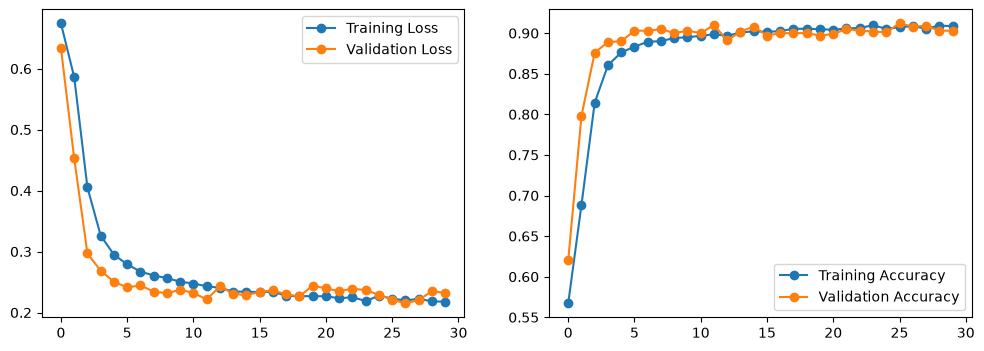

In [11]:
x_arr = np.arange(num_epochs)
fig = plt.figure(figsize=(12,4))
ax=fig.add_subplot(1,2,1)
ax.plot(x_arr, loss_history_train, '-o', label='Training Loss')
ax.plot(x_arr, loss_history_valid, '-o', label='Validation Loss')
ax.legend()

ax=fig.add_subplot(1,2,2)
ax.plot(x_arr, accuracy_history_train, '-o', label='Training Accuracy')
ax.plot(x_arr, accuracy_history_valid, '-o', label='Validation Accuracy')
ax.legend();

**Problem**: Describe why you use the `is_correct` condition that you do.

`is_correct` effectively just uses a boolean check (with a threshold of 0.5) to determine if our probability prediction is correct. 0.5 is essentially a random guess. If we're 50+% confident that the person is smiling in the image, we return a label of 1 and if we're less then we return a label of 0. These are compared to the true labels via the == condition and `is_correct` effectively returns an array of 0s or 1s with 1 saying the prediction is correct and 0 if not.


## Analyzing the Test Data

In [ ]:
accuracy_history_test = 0.
with torch.no_grad(): # don't optimize at this point, i.e. keep all weights fixed 
    for x_batch, y_batch in test_dl:
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)
        pred = model(x_batch)[:, 0]
        is_correct = ( (pred>=.5).float() == y_batch).float()
        accuracy_history_test += is_correct.sum()
    accuracy_history_test /= len(test_dl.dataset)
    
    print(f"Final accuracy: {accuracy_history_test:.4f} ")

pred = model(x_batch)[:, 0] * 100. # these are the computed probabilities of whether a test image is smiling or not

Final ccuracy: 0.9124 


**Problem**: Using the code above that displayed the images in the training data, and using the fact that `y_batch[jj]==1` if and only if an image is labeled as 'smiling', print out ten test images with a label on each image indicating whether they are actually smiling or not.  Along with this, also print the probability your model finds for whether they are smiling.  

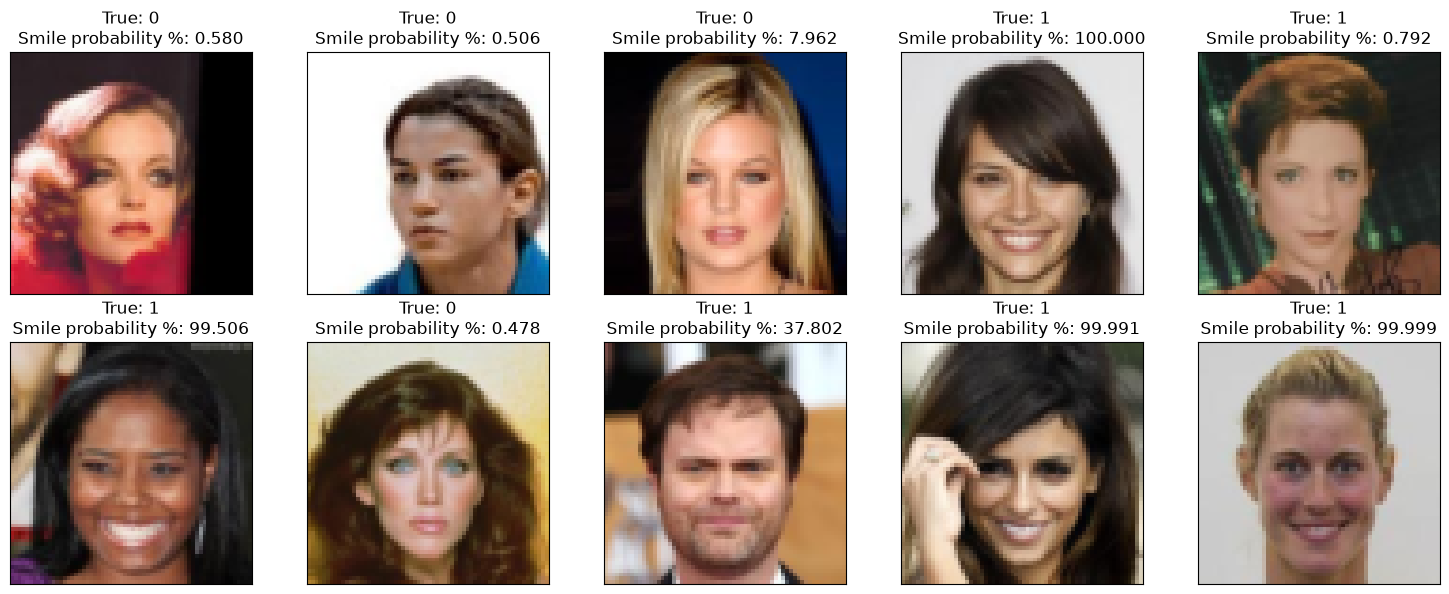

In [19]:
img_batch, label_batch = x_batch, y_batch # pull the last batch from above

# loop through the first 10 images, print out their labels and model probabilities
fig, axs = plt.subplots(2, 5, figsize=(15, 6))

for jj, ax in enumerate(axs.flat):
    img = img_batch[jj].cpu().permute(1, 2, 0)
    true_label = label_batch[jj].item()
    probability = pred[jj].item()

    ax.imshow(img)
    ax.set_title(
        f"True: {int(true_label)}\n"
        f"Smile probability %: {probability:.3f}"
    )
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()